---
title: "Лекція 5. Інтерпретація моделей і поясненний штучний інтелект у науковому дослідженні"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


## Мета лекції

Сформувати розуміння поясненності моделей машинного навчання як *окремого об'єкта наукової перевірки*: від постановки питання про поведінку моделі до вибору методу пояснення, оцінювання його достовірності та визначення меж наукового висновку.

## Очікувані результати навчання

Після лекції аспірант зможе:

1. Розрізняти інтерпретованість моделі, пояснення прогнозу та причинне пояснення явища.
2. Обґрунтовувати вибір глобальних і локальних методів пояснення.
3. Пояснювати принципи permutation importance, PDP, ICE, LIME та SHAP.
4. Перевіряти чутливість пояснень до кореляцій, вибору фонової вибірки й випадковості.
5. Формулювати наукове твердження, яке не виходить за межі доказової сили XAI.

## План лекції

1. Пояснення як дослідницьке питання.
2. Інтерпретованість і post-hoc пояснення.
3. Глобальні та локальні методи.
4. Permutation importance.
5. PDP та ICE.
6. Локальні сурогатні моделі (LIME).
7. Адитивні атрибуції (SHAP).
8. Надійність пояснень: fidelity, stability, sensitivity.
9. Корельовані ознаки та вибір референсного розподілу.
10. Наукові твердження, XAI-аудит і перехід до причинного висновку.

Ключові джерела: [@rudin2019stop; @hastie2009elements; @breiman2001two].

# 1. Що саме ми пояснюємо?

Питання *«Чому модель передбачила клас 1?»* принципово відрізняється від питання *«Чому в реальному світі виникла подія класу 1?»*.

Перше стосується механізму обчислення $f(x)$, друге -- механізму породження даних. Висока прогностична якість та переконливе XAI-пояснення самі по собі не ідентифікують причинних ефектів [@pearl2009causality; @rudin2019stop].

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Дані та<br/>ознаки") --> B("Навчена<br/>модель")
 B --> C("Прогноз")
 B --> D("XAI:<br/>поведінка моделі")
 E("Механізм<br/>явища") --> A
 D -.-> F("Не дорівнює<br/>причинному ефекту")
```

*Інтерпретованість (interpretability)* -- здатність людини зрозуміти логіку моделі в межах заданої задачі. *Поясненність (explainability)* -- здатність отримати обґрунтоване пояснення конкретної поведінки моделі. Термінологія в літературі не повністю уніфікована; у цьому курсі використовуємо ці операційні розрізнення.

# 2. Прозорі моделі та post-hoc пояснення

*Прозорі (intrinsically interpretable) моделі* -- невеликі дерева рішень, лінійні та адитивні моделі, короткі набори правил -- мають структуру, яку можна аналізувати без окремого апроксиматора.

*Post-hoc пояснення* застосовують після навчання довільної моделі. Воно може бути корисним, але є *додатковим обчислювальним об'єктом*, що потребує валідації. Для задач високого ризику перевага інтерпретованих моделей за зіставної якості може бути принциповою [@rudin2019stop].

Для логістичної регресії:

$$
P(Y=1\mid x)=\sigma(\beta_0+\beta^\top x),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

За інших рівних умов збільшення $x_j$ на одиницю змінює *логарифм шансів прогнозу* на $\beta_j$. Але це не доводить причинного впливу $X_j$ на $Y$.

# 3. Глобальні та локальні пояснення

| Вимір | Глобальне пояснення | Локальне пояснення |
|---|---|---|
| Об'єкт | Поведінка моделі на популяції | Прогноз для конкретного $x$ |
| Питання | Які ознаки загалом впливають на якість/прогнози? | Які ознаки пов'язані з цим прогнозом? |
| Приклад | Permutation importance, PDP | LIME, SHAP |
| Обмеження | Залежність від вибірки | Залежність від локального оточення |

Один і той самий метод може мати різні варіанти використання: наприклад, SHAP-значення для багатьох спостережень агрегують для глобального аналізу.

# 4. Permutation importance: важливість як втрата якості

Перестановочна важливість (permutation feature importance) оцінює, наскільки погіршується обрана метрика після випадкового перемішування однієї ознаки.

Нехай $S(f,D)$ -- метрика, для якої *більше означає краще*. Тоді:

$$
I_j=S(f,D)-\mathbb{E}_{\pi_j}[S(f,D_{\pi_j})],
$$

де $D_{\pi_j}$ -- вибірка з переставленою ознакою $j$.

Це *важливість для конкретної моделі, метрики та вибірки*, а не універсальна міра важливості ознаки у природі. За сильно корельованих ознак перестановка може створювати малоймовірні комбінації та занижувати або спотворювати індивідуальні оцінки.

## Навчальний експеримент: прогноз і важливість ознак

Використаємо синтетичні дані, де дві ознаки є сильно корельованими. Навчальну і тестову вибірки розділимо *до* навчання. Тестову частину використовуємо лише для оцінювання за фіксованого протоколу.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import roc_auc_score

SEED = 42
rng = np.random.default_rng(SEED)
n = 1600

x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.12, size=n)  # Корельована копія
x3 = rng.normal(size=n)
x4 = rng.normal(size=n)
logit = 1.8*x1 + 0.9*x3 - 0.7*x4
prob = 1 / (1 + np.exp(-logit))
y = rng.binomial(1, prob)

X = pd.DataFrame({
    "signal": x1, "correlated_copy": x2,
    "secondary": x3, "negative": x4
})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
model = RandomForestClassifier(
    n_estimators=120, min_samples_leaf=8,
    random_state=SEED, n_jobs=1
)
model.fit(X_train, y_train)
print("Test ROC AUC:", round(
    roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]), 3
))
display(X_train.corr().round(2))


Test ROC AUC: 0.852


,signal,correlated_copy,secondary,negative
signal,1.00,0.99,0.03,-0.02
correlated_copy,0.99,1.00,0.03,-0.01
secondary,0.03,0.03,1.00,0.09
negative,-0.02,-0.01,0.09,1.00


Важливо: у генераторі відома формула утворення мітки. У реальному дослідженні вона зазвичай невідома. Саме тому не можна ототожнювати ранжування ознак моделлю з доказом механізму явища.


,feature,mean_drop,sd
0,signal,0.137,0.016
2,secondary,0.058,0.013
1,correlated_copy,0.050,0.009
3,negative,0.044,0.008


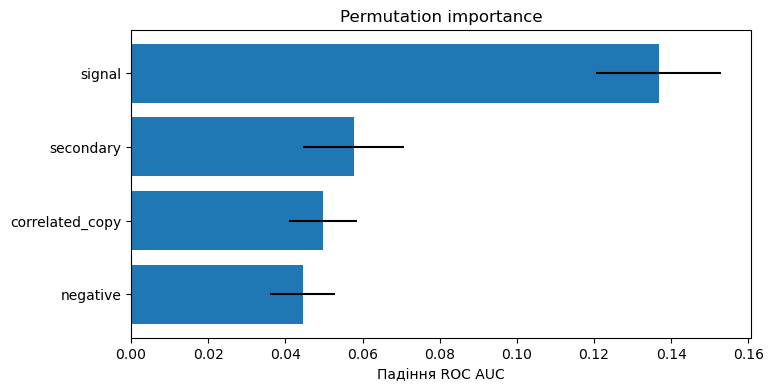

In [2]:
importance = permutation_importance(
    model, X_test, y_test,
    scoring="roc_auc", n_repeats=12, random_state=SEED, n_jobs=1
)
imp = pd.DataFrame({
    "feature": X.columns,
    "mean_drop": importance.importances_mean,
    "sd": importance.importances_std
}).sort_values("mean_drop", ascending=False)
display(imp.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp["feature"], imp["mean_drop"], xerr=imp["sd"])
ax.invert_yaxis()
ax.set(xlabel="Падіння ROC AUC", title="Permutation importance")
plt.show()


# 5. Partial dependence та ICE

*Часткова залежність (partial dependence plot, PDP)* для ознаки $X_j$:

$$
PD_j(z)=\mathbb{E}_{X_{-j}}\left[f(z,X_{-j})\right].
$$

PDP усереднює прогнози після штучної фіксації $X_j=z$. *Індивідуальні умовні очікування (individual conditional expectation, ICE)* показують такі криві окремо для спостережень.

PDP не є функцією причинного ефекту. Якщо $X_j$ сильно пов'язана з іншими ознаками, зміна лише $X_j$ може створювати нереалістичні точки.

## Приклад PDP та ICE


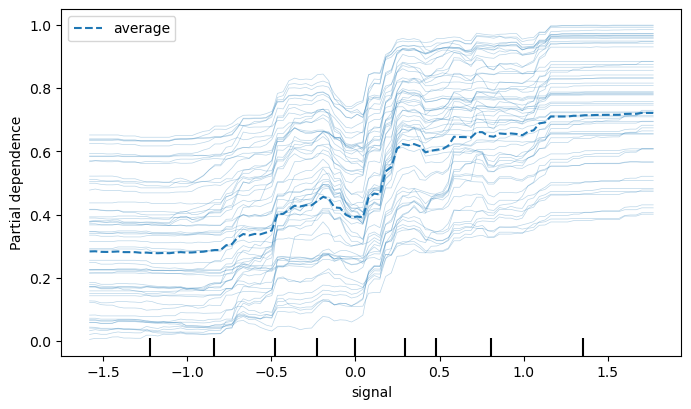

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
PartialDependenceDisplay.from_estimator(
    model, X_test, ["signal"],
    kind="both", subsample=60, random_state=SEED, ax=ax
)
plt.show()


Порівняйте усереднену криву з окремими ICE-кривими. Відмінність нахилів свідчить про неоднорідність поведінки *моделі*, а не автоматично про гетерогенні причинні ефекти.

# 6. LIME: локальна апроксимація складної моделі

*Локальні інтерпретовані модельно-незалежні пояснення (local interpretable model-agnostic explanations, LIME)* апроксимують модель $f$ простою функцією $g$ в околі спостереження $x$:

$$
g_x^\ast=\arg\min_{g\in G}
\left\{\mathcal{L}(f,g,\pi_x)+\Omega(g)\right\}.
$$

Тут $\pi_x$ -- вагова функція близькості до $x$, $\mathcal{L}$ -- локальна втрата апроксимації, $\Omega(g)$ -- штраф за складність.

Алгоритм: сформувати локальні збурення, отримати прогнози $f$, зважити їх за близькістю, навчити простий сурогат $g$. Локальна якість апроксимації *не гарантує* достовірності поза вибраним околом.

## Ручний мініприклад

Нехай модель повернула для чотирьох близьких точок:

| $x_1$ | $x_2$ | $f(x)$ |
|---:|---:|---:|
| 0 | 0 | 0.20 |
| 1 | 0 | 0.50 |
| 0 | 1 | 0.30 |
| 1 | 1 | 0.60 |

Лінійний локальний сурогат $g(x)=b_0+b_1x_1+b_2x_2$ точно відтворює ці чотири значення за $b_0=0.20$, $b_1=0.30$, $b_2=0.10$. Отже, *в цьому околі та за такого кодування* зміна першої ознаки пов'язана зі зміною прогнозу на 0.30, другої -- на 0.10.

Це не причинні ефекти: ми аналізуємо лише числову поведінку $f$ на вибраних точках.

# 7. SHAP: адитивні атрибуції

*SHAP (SHapley Additive exPlanations)* використовує ідею значення Шеплі для розподілу різниці між прогнозом і базовим значенням між ознаками.

Для адитивного представлення:

$$
f(x)=\phi_0+\sum_{j=1}^{p}\phi_j(x),
$$

де $\phi_0$ -- референсне значення прогнозу, а $\phi_j(x)$ -- внесок ознаки за визначеним правилом обліку її наявності/відсутності.

У загальному вигляді для множини ознак $F$:

$$
\phi_j=\sum_{S\subseteq F\setminus\{j\}}
\frac{|S|!(p-|S|-1)!}{p!}
\left[v(S\cup\{j\})-v(S)\right].
$$

Тут $v(S)$ -- значення функції коаліції; спосіб визначення «відсутньої» ознаки є важливим припущенням, особливо за залежних ознак.

## Ручний приклад для двох ознак

Нехай $v(\varnothing)=0.20$, $v(\{1\})=0.50$, $v(\{2\})=0.30$, $v(\{1,2\})=0.70$. Тоді:

$$
\phi_1=\frac12(0.50-0.20)+\frac12(0.70-0.30)=0.35,
$$

$$
\phi_2=\frac12(0.30-0.20)+\frac12(0.70-0.50)=0.15.
$$

Перевірка адитивності: $0.20+0.35+0.15=0.70$.

**Ключове застереження:** числа $\phi_j$ характеризують *розподіл внесків за конкретним правилом $v(S)$*, а не «силу причинного впливу».

# 8. Надійність пояснення як предмет експерименту

Для XAI недостатньо показати один переконливий графік. Потрібно визначити вимірювані властивості пояснення:

- *Точність апроксимації (fidelity)* -- наскільки сурогат відтворює поведінку вихідної моделі.
- *Стабільність (stability)* -- наскільки пояснення змінюється за допустимих змін seed, вибірки чи параметрів методу.
- *Чутливість (sensitivity)* -- чи реагує пояснення на зміни, які повинні бути змістовними.
- *Робастність (robustness)* -- чи зберігаються ключові висновки за обґрунтованих змін протоколу.
- *Предметна придатність* -- чи відповідає пояснення реальному дослідницькому питанню.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart TD
 A("Навчена модель") --> B("Метод пояснення")
 B --> C("Пояснення")
 C --> D("Fidelity")
 C --> E("Stability")
 C --> F("Sensitivity")
 D --> G("Аудит XAI")
 E --> G
 F --> G
 G --> H("Обмежене<br/>наукове твердження")
```

## Обчислювальний приклад: стійкість ранжування

Повторимо permutation importance з різними seed, не перенавчаючи модель. Оцінюємо *стійкість процедури пояснення за фіксованої моделі*, а не стійкість до зміни навчальних даних.


In [4]:
importance_runs = []
for seed in range(10):
    res = permutation_importance(
        model, X_test, y_test, scoring="roc_auc",
        n_repeats=5, random_state=seed, n_jobs=1
    )
    importance_runs.append(res.importances_mean)
importance_runs = np.asarray(importance_runs)

stability_table = pd.DataFrame({
    "feature": X.columns,
    "mean_importance": importance_runs.mean(axis=0),
    "sd_across_runs": importance_runs.std(axis=0, ddof=1)
}).sort_values("mean_importance", ascending=False)
display(stability_table.round(4))


,feature,mean_importance,sd_across_runs
0,signal,0.1318,0.0054
2,secondary,0.0606,0.0045
1,correlated_copy,0.0455,0.0029
3,negative,0.0379,0.0061


# 9. Корельовані ознаки та референсний розподіл

У нашому прикладі `signal` і `correlated_copy` майже дублюють інформацію. Модель може розподіляти прогностичний внесок між ними, а permutation importance може оцінювати кожну окремо як менш важливу, ніж їхню спільну інформацію.

Так само SHAP залежить від того, як визначено відсутні ознаки: маргінальне усереднення, умовний розподіл, інтервенційна схема тощо. Різні постановки відповідають *різним питанням*, а не просто різним бібліотекам.

Практичні перевірки:

1. Повторити пояснення на незалежній тестовій вибірці.
2. Перевірити групи корельованих ознак.
3. Порівняти альтернативні допустимі фонові розподіли.
4. Зазначити, чи пояснюються ймовірності, log-odds або інший вихід моделі.
5. Зафіксувати версію моделі, seed і конфігурацію методу.

# 10. Коли XAI створює ілюзію наукового знання

Розглянемо твердження:

> «SHAP показав, що нічна активність є причиною ботоподібної поведінки».

Це *методологічно некоректно*. SHAP може показати, що ознака пов'язана з прогнозом навченої моделі за певним способом атрибуції. Для висновку про причинність потрібні причинне питання, припущення про механізм породження даних, причинний граф та відповідний дизайн [@pearl2009causality; @hernan2020causal].

Коректніше:

> «За фіксованої моделі та вибраного фону ознака нічної активності мала додатний внесок у прогноз для розглянутих облікових записів; стійкість і узагальнюваність цього пояснення потребують окремої перевірки».

# 11. XAI як частина доказового ланцюга дослідження

| Елемент | Контрольне питання |
|---|---|
| RQ | Яку властивість моделі потрібно пояснити? |
| Об'єкт пояснення | Окремий прогноз, група чи модель загалом? |
| Метод | Чому саме він відповідає RQ? |
| Дані | На якій вибірці обчислено пояснення? |
| Фон | Який референсний розподіл використано? |
| Валідація | Які fidelity, stability, sensitivity перевірено? |
| Висновок | Що саме підтверджено, а що -- ні? |

# 12. Зв'язок із дисертаційним дослідженням

У попередніх роботах аспірант створив *Research Specification v0.1*, *Experiment Design v0.2*, *Evidence Audit v0.3* та *Structure Validation v0.4*. Наступний крок -- *Explanation Audit v0.5*.

Для власного дослідження потрібно зафіксувати:

- яку саме модель або закономірність пояснюємо;
- чому пояснення є необхідним для наукового питання;
- які методи є придатними та які припущення вони використовують;
- які перевірки надійності виконуватимуться;
- яких висновків пояснення *не дозволяє* робити.

# 13. Перехід до причинного висновку

XAI відповідає на питання про *поведінку моделі*. Причинний висновок (causal inference) відповідає на питання про *наслідки втручання у систему*. Цей перехід потребує нового формального апарату, який розглядатимемо в лекції 6.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Прогноз:<br/>що відбудеться?") --> B("XAI:<br/>чому так прогнозує модель?")
 B --> C("Причинне питання:<br/>що зміниться після втручання?")
 C --> D("Causal inference:<br/>ідентифікація та оцінювання")
```

# Питання для самоконтролю

1. Чим відрізняються інтерпретованість і поясненність?
2. Чому пояснення прогнозу не є причинним поясненням?
3. Коли прозора модель може бути кращою за post-hoc пояснення?
4. Що вимірює permutation importance?
5. Чому кореляція ознак ускладнює перестановочну важливість?
6. Як побудовано PDP і ICE?
7. Чому PDP може оцінювати нереалістичні комбінації ознак?
8. У чому полягає ідея LIME?
9. Що таке локальна fidelity?
10. Як обчислюють значення Шеплі для двох ознак?
11. Чому SHAP залежить від визначення фонової вибірки?
12. Чим stability пояснення відрізняється від stability моделі?
13. Які загрози валідності виникають під час постфактум-інтерпретації?
14. Як правильно сформулювати наукове твердження за результатами XAI?
15. Чому причинний висновок потребує окремого дизайну?

# Висновки

Пояснення моделі є *гіпотезою про її поведінку*, що потребує перевірки. Важливість ознак, локальні атрибуції та графіки часткової залежності дають корисні свідчення, але їхня наукова цінність визначається відповідністю RQ, обґрунтованістю припущень і стійкістю результатів.

# Література та ресурси

Основні джерела: [@rudin2019stop; @hastie2009elements; @breiman2001two; @pearl2009causality; @hernan2020causal].

Додатково: [scikit-learn: permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html), [Partial Dependence and ICE](https://scikit-learn.org/stable/modules/partial_dependence.html), [SHAP documentation](https://shap.readthedocs.io/).

::: {#refs}
:::
